# N162 · Embedding and update-preview features for H1

Wait for N161 to finish. Reuse its exact two deployment pools, the same warm
learner, chronological order, seeds and fixed-rate controls. Reuse the N161
uncalibrated positive-gain H1 trajectory as the direct reference. Train only two
new challengers on each pool, 30,464 decisions per challenger across both pools.

Both challengers keep the 13 base inputs, action set {skip, 1/4, 1}, strictly
positive loss and RankMe gains, and the half-weight RankMe score. One adds the
current embedding norm, eight fixed normalized projections and maximum/mean
cosine similarity to the observed bank. The other adds candidate training-view
loss, gradient norm, gradient–momentum cosine and proposed AdamW displacement
magnitude. It measures one backward pass before each decision and applies that
same gradient if chosen. A skipped preview leaves learner and optimizer intact.
The two feature groups are tested separately. No labeled gradient is used.

Recover both feature groups on the exact N161 offline reference states and reuse
its measured paired action outcomes. Compare frozen prediction on the same
held-out origins against the base predictor and persistence. Also compare each
selector with expected random assignment of the same rates within each clip.
Report offline results alongside both scheduled online development tests.

Online, each rate head learns from its executed outcomes. The separate simple
next-arrival forecaster continues learning on every arm. Primary stream outcomes
are incoming pre-update reconstruction over all arrivals and actual RankMe on
the same context panel before and after accepted steps. Plot measured loss,
training loss, RankMe and RMSE versus persistence. Log feature time, dose, rate
counts and guard failures. The reused online references can differ in update
counts and LR dose. Exact dose matching is performed only in the offline
same-origin diagnostic. The two source pools are reused development data.


## Live status

**complete** · Both feature challengers and reused reference comparisons saved

Updated UTC `2026-11-06T21:04:02+00:00` · PID `46816`.

N161 · pool_2/mpc_loss · 14,976/15,232 decisions. 121,600/121,856 physical decisions. Extrapolated remaining **0 min**.

All 60,928 challenger decisions are complete.

Free disk **17.1 GiB** with a 3 GiB reserve.

## Matched offline held-out origins

RMSE is forecast / persistence. Gains compare the measured selected action to skip.

| Features | Loss RMSE | RankMe RMSE | Loss / rank direction accuracy | Both gains / selected | Loss gain | Matched-random loss gain |
|---|---:|---:|---:|---:|---:|---:|
| base | 0.004830 / 0.004544 | 0.007963 / 0.007767 | 71.7% / 50.5% | 28/70 | +0.002173 | +0.002450 |
| embedding | 0.005135 / 0.004544 | 0.010430 / 0.007767 | 79.2% / 53.8% | 37/82 | +0.002711 | +0.002933 |
| preview | 0.003190 / 0.004544 | 0.007992 / 0.007767 | 74.5% / 54.2% | 31/62 | +0.002257 | +0.002104 |

## Online trajectories

N161 references have full coverage. Challenger rows can be partial.

| Stream / arm | Decisions | Quarter / nominal | Mean incoming loss | Mean RankMe | Accepted training loss | Feature seconds |
|---|---:|---:|---:|---:|---:|---:|
| pool_1/full_admission | 15,232 | 0 / 15,232 | 0.78534 | 1.19100 | 0.77030 | — |
| pool_1/quarter_admission | 15,232 | 15,232 / 0 | 0.79488 | 1.51785 | 0.77578 | — |
| pool_1/mpc_neither | 15,232 | 1,725 / 149 | 0.87712 | 1.59983 | 0.83360 | — |
| pool_2/full_admission | 15,232 | 0 / 15,232 | 0.82131 | 1.27766 | 0.80445 | — |
| pool_2/quarter_admission | 15,232 | 15,232 / 0 | 0.83104 | 1.57302 | 0.81085 | — |
| pool_2/mpc_neither | 15,232 | 831 / 865 | 0.89220 | 1.57973 | 0.91015 | — |
| pool_1/embedding | 15,232 | 1,089 / 495 | 0.87378 | 1.58202 | 0.87356 | 662.2 |
| pool_1/preview | 15,232 | 619 / 309 | 0.88941 | 1.57881 | 0.80729 | 1526.5 |
| pool_2/embedding | 15,232 | 539 / 454 | 0.92983 | 1.52280 | 0.82203 | 628.3 |
| pool_2/preview | 15,232 | 622 / 388 | 0.87795 | 1.61779 | 0.86858 | 1401.0 |

## Observed action H1 forecast errors

| Stream / arm | Updates | Loss RMSE / persistence | RankMe RMSE / persistence | Guard misses |
|---|---:|---:|---:|---:|
| pool_1/mpc_neither | 1,874 | 0.0041334 / 0.005037 | 0.0054439 / 0.0057535 | 1107 |
| pool_2/mpc_neither | 1,696 | 0.0048278 / 0.006224 | 0.01802 / 0.018176 | 1076 |
| pool_1/embedding | 1,584 | 0.0040631 / 0.0047056 | 0.015029 / 0.01487 | 933 |
| pool_1/preview | 928 | 0.0063258 / 0.0087063 | 0.0082721 / 0.0084546 | 582 |
| pool_2/embedding | 993 | 0.0041672 / 0.0052528 | 0.019113 / 0.01974 | 536 |
| pool_2/preview | 1,010 | 0.0067136 / 0.0086392 | 0.011849 / 0.01248 | 634 |

## Final equal-pool comparison

| Arm | Incoming loss | Contextual RankMe | Audit loss | Audit RankMe | Updates | LR dose |
|---|---:|---:|---:|---:|---:|---:|
| Nominal · N161 | 0.803326 | 1.23433 | 1.224018 | 1.98724 | 30,464 | 30464.0 |
| Quarter rate · N161 | 0.812959 | 1.54543 | 1.038652 | 2.55335 | 30,464 | 7616.0 |
| Base H1 · N161 | 0.884662 | 1.58978 | 0.941408 | 2.51751 | 3,570 | 1653.0 |
| Embedding context | 0.901806 | 1.55241 | 0.946073 | 2.33181 | 2,577 | 1356.0 |
| Update preview | 0.883678 | 1.59830 | 0.899388 | 2.32168 | 1,938 | 1007.2 |

### Actual loss and RankMe

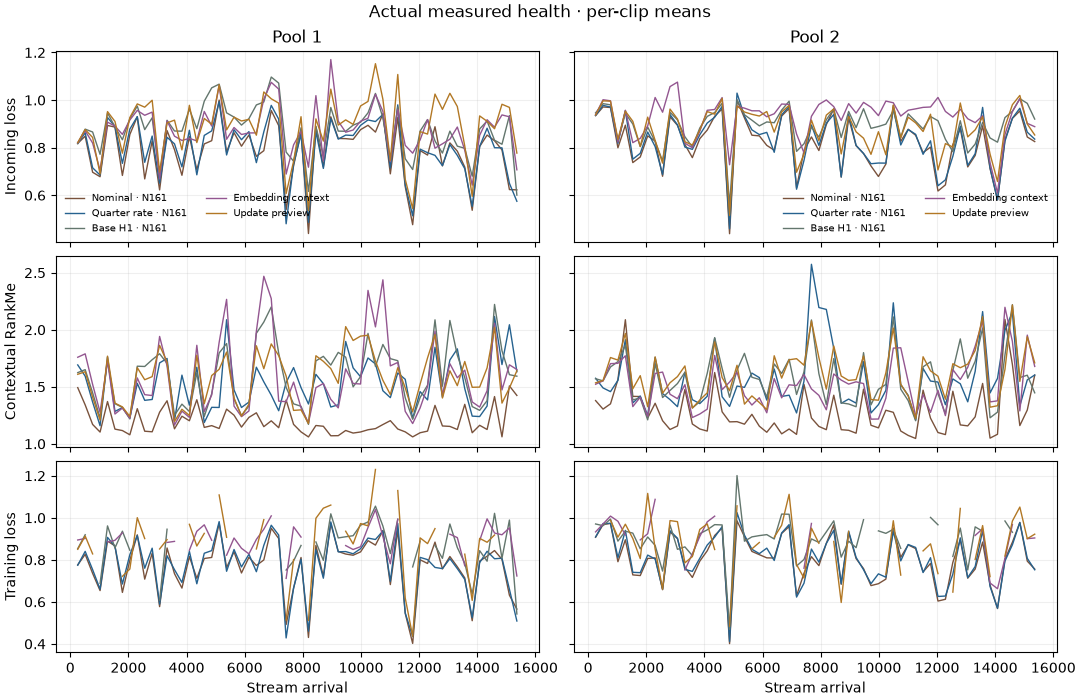

### Next-arrival H1 RMSE

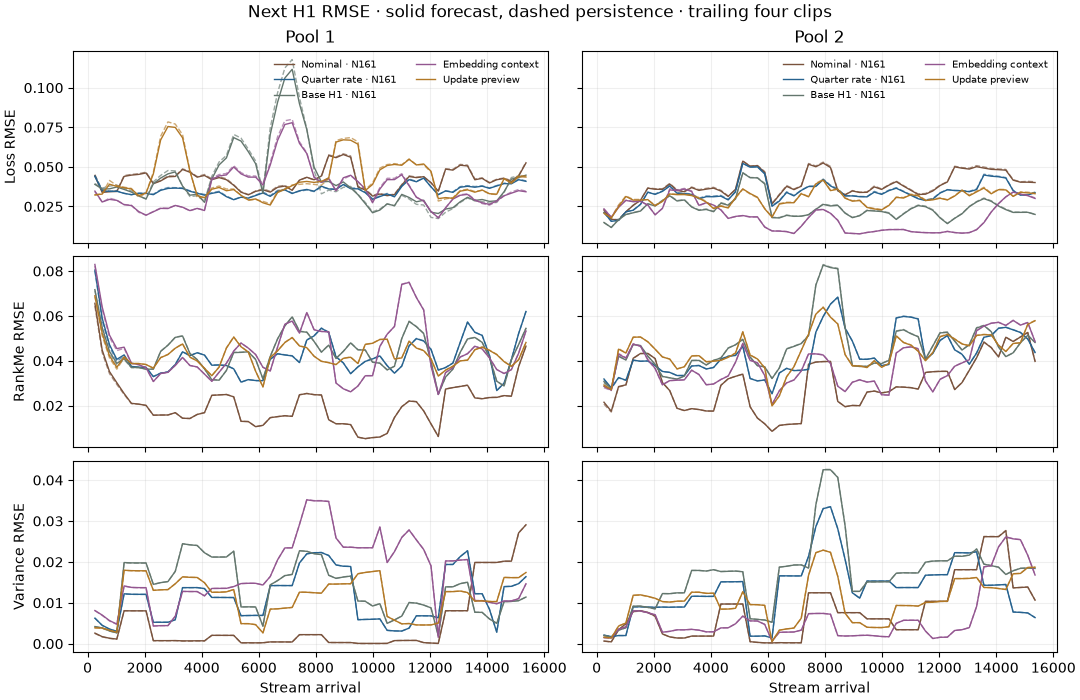

### Action H1 RMSE

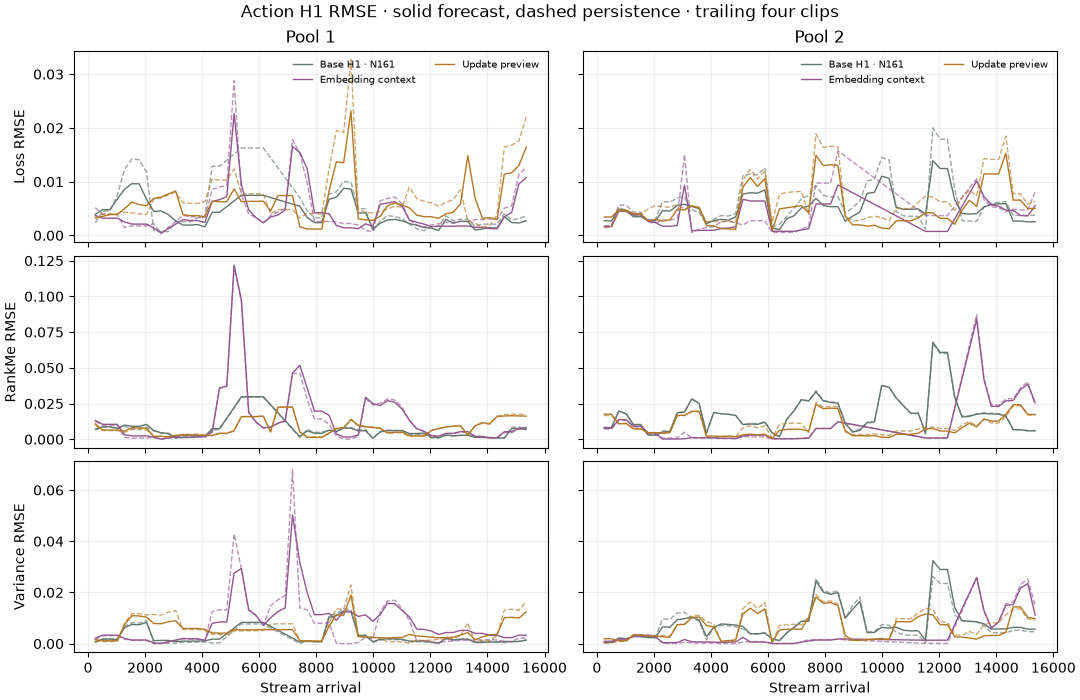